In [133]:
# 1. Standard Python Libraries
import json
from pathlib import Path

# 2. Data Analysis and Visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 3. TensorFlow and Keras
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

# Models
from tensorflow.keras.models import (Sequential,load_model,clone_model)

# Neural Network Layers
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    GlobalAveragePooling2D,
    Dense,
    Activation,
    Dropout,
    BatchNormalization,
    RandomFlip,
    RandomTranslation,
    RandomContrast
)

# Callbacks
from tensorflow.keras.callbacks import (EarlyStopping,ReduceLROnPlateau,ModelCheckpoint)

# Regularization
from tensorflow.keras.regularizers import l2

# 4. Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,classification_report,recall_score)


# Load Data

In [128]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

In [129]:
print("Training Images:", x_train.shape)
print("Training Labels:", y_train.shape)

print("Test Images:", x_test.shape)
print("Test Labels:", y_test.shape)

Training Images: (50000, 32, 32, 3)
Training Labels: (50000, 1)
Test Images: (10000, 32, 32, 3)
Test Labels: (10000, 1)


In [4]:
print("Data Type:", x_train.dtype)
print("Pixel Range:", x_train.min(),"-",x_train.max())
print("Unique Labels:", np.unique(y_train))


Data Type: uint8
Pixel Range: 0 - 255
Unique Labels: [0 1 2 3 4 5 6 7 8 9]


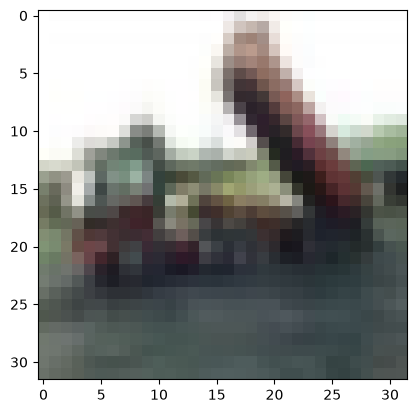

In [5]:
plt.imshow(x_train[2])

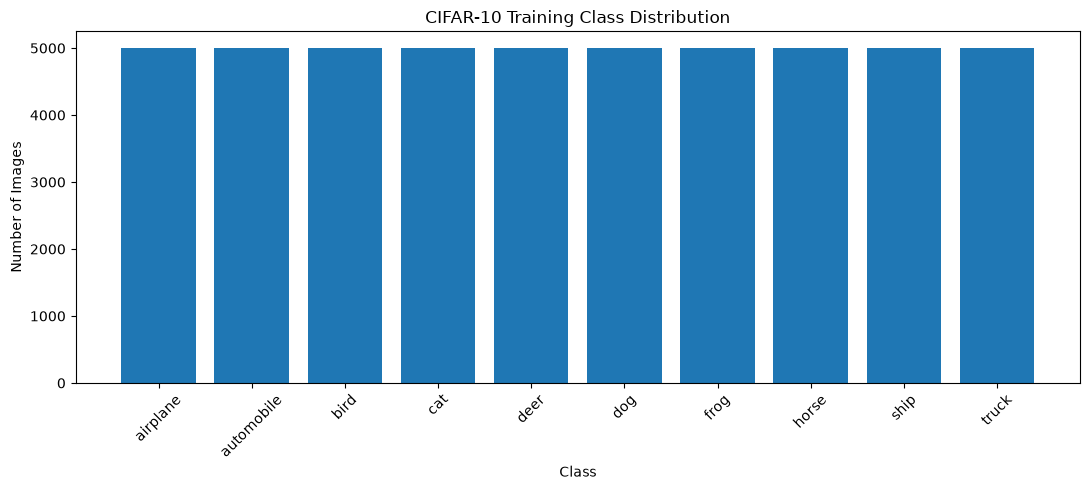

In [6]:
# CIFAR-10 Class Names
CLASS_NAMES = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# Count images in each class
class_counts = np.bincount(y_train.flatten(), minlength=10)

# Visualize Class Distribution
plt.figure(figsize=(11, 5))
plt.bar(CLASS_NAMES, class_counts)

plt.title("CIFAR-10 Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
#Normalization
x_train = x_train.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

In [8]:
# One-hot encoding target labels
y_cat_train = to_categorical(y_train, num_classes=10)
y_cat_test = to_categorical(y_test, num_classes=10)
y_cat_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]])

# Split Data

In [11]:
x_fit, x_val, y_fit, y_val = train_test_split(x_train,y_cat_train,test_size=0.1,random_state=42,stratify=y_train.ravel())

# Baseline model

In [ ]:
model = Sequential([
    Input(shape=(32, 32, 3)),

    Conv2D(filters=32, kernel_size=(4, 4), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(filters=64, kernel_size=(4, 4), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(256, activation="relu"),
    Dense(10, activation="softmax")
])

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

In [ ]:
early_stop = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)

In [13]:
model.fit(x_fit,y_fit,epochs=15,batch_size=64,validation_data=(x_val, y_val),callbacks=[early_stop])

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.4437 - loss: 1.5377 - val_accuracy: 0.5276 - val_loss: 1.3374
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.5852 - loss: 1.1715 - val_accuracy: 0.6044 - val_loss: 1.1460
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6417 - loss: 1.0235 - val_accuracy: 0.6162 - val_loss: 1.1096
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6833 - loss: 0.9106 - val_accuracy: 0.6532 - val_loss: 0.9955
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7179 - loss: 0.8145 - val_accuracy: 0.6670 - val_loss: 0.9865
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7459 - loss: 0.7308 - val_accuracy: 0.6806 - val_loss: 0.9382
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7747 - loss: 0.6476 - val_accuracy: 0.6878 - val_loss: 0.9295
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7977 - loss: 0.5772 - val_accu

In [14]:
losses = pd.DataFrame(model.history.history)
losses

,accuracy,loss,val_accuracy,val_loss
0,0.443733,1.537695,0.5276,1.337440
1,0.585222,1.171547,0.6044,1.145975
2,0.641711,1.023478,0.6162,1.109554
3,0.683311,0.910634,0.6532,0.995474
4,0.717867,0.814474,0.6670,0.986497
5,0.745933,0.730776,0.6806,0.938169
6,0.774667,0.647619,0.6878,0.929507
7,0.797711,0.577245,0.6728,1.000150
8,0.824689,0.503316,0.6752,1.016697
9,0.850556,0.433204,0.6846,1.057387


<Axes: >

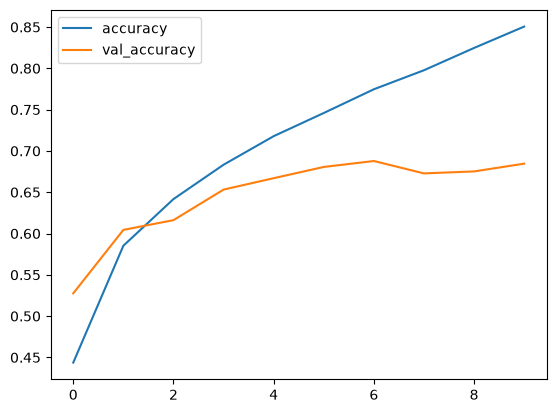

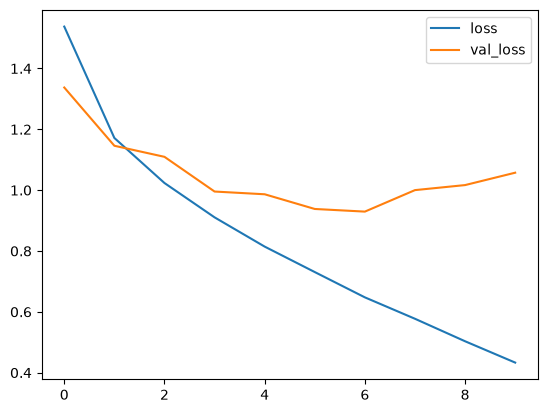

In [15]:
losses[["accuracy","val_accuracy"]].plot()
losses[["loss","val_loss"]].plot()

In [ ]:
best_epoch = np.argmin(model.history.history["val_loss"]) + 1

val_loss, val_accuracy = model.evaluate(x_val,y_val,verbose=0)

print("Best Epoch:", best_epoch)
print("Validation Loss:", round(val_loss, 4))
print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")


Best Epoch: 7
Validation Loss: 0.9295
Validation Accuracy: 68.78 %


In [17]:
model.evaluate(x_test, y_cat_test, verbose=0)

[0.9568614363670349, 0.6823999881744385]

In [18]:
Path("models").mkdir(exist_ok=True)
model.save("models/baseline_cnn.keras")
print("Baseline CNN saved successfully!")

Baseline CNN saved successfully!


# Experiment 02 -  Dropout = 0.3


In [19]:
# Build a NEW model from scratch
dropout_model = Sequential([
    Input(shape=(32, 32, 3)),

    Conv2D(32, (4, 4), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (4, 4), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(256, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

In [20]:
dropout_model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [21]:
dropout_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       409,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 446,826 (1.70 MB)

 Trainable params: 446,826 (1.70 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history_dropout = dropout_model.fit(
    x_fit,
    y_fit,
    epochs=15,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stop]
)

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.4319 - loss: 1.5643 - val_accuracy: 0.5456 - val_loss: 1.2644
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.5602 - loss: 1.2366 - val_accuracy: 0.6232 - val_loss: 1.1072
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6145 - loss: 1.1028 - val_accuracy: 0.6308 - val_loss: 1.0622
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6528 - loss: 0.9923 - val_accuracy: 0.6736 - val_loss: 0.9460
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6807 - loss: 0.9131 - val_accuracy: 0.6806 - val_loss: 0.9240
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.7019 - loss: 0.8457 - val_accuracy: 0.6804 - val_loss: 0.9066
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.7233 - loss: 0.7846 - val_accuracy: 0.6946 - val_loss: 0.8755
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7426 - loss: 0.7308 - val_accu

In [23]:

val_loss, val_acc = dropout_model.evaluate(
    x_val,
    y_val,
    verbose=0
)

print("Baseline Validation Accuracy: 67.96%")
print("Baseline Validation Loss: 0.9124")

print("Dropout Validation Accuracy:", round(val_acc * 100, 2), "%")
print("Dropout Validation Loss:", round(val_loss, 4))


Baseline Validation Accuracy: 67.96%
Baseline Validation Loss: 0.9124
Dropout Validation Accuracy: 70.36 %
Dropout Validation Loss: 0.8739


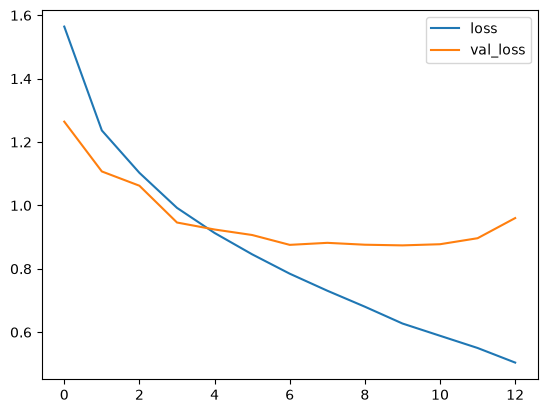

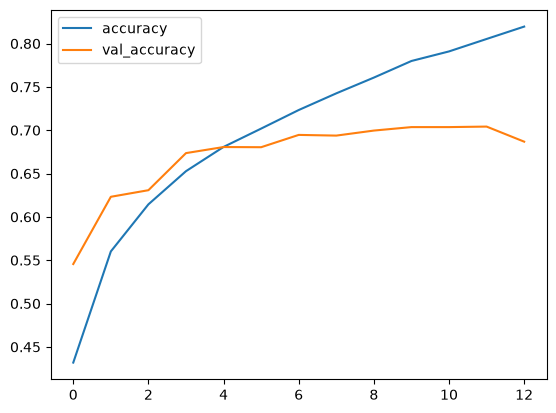

In [24]:
losses_dropout = pd.DataFrame(history_dropout.history)

losses_dropout[["loss", "val_loss"]].plot()
losses_dropout[["accuracy", "val_accuracy"]].plot()

plt.show()

# Experiment 03 - Dropout + RandomFlip

In [134]:
flip_model = Sequential([
    Input(shape=(32, 32, 3)),

    RandomFlip("horizontal"),

    Conv2D(32, (4, 4), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (4, 4), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(256, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])
flip_model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])
flip_model.summary()


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_10 (RandomFlip)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_44 (Conv2D)              │ (None, 11, 11, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 256)            │       409,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 446,826 (1.70 MB)

 Trainable params: 446,826 (1.70 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
history_flip = flip_model.fit(
    x_fit,
    y_fit,
    epochs=15,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stop]
)

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.4219 - loss: 1.5961 - val_accuracy: 0.5354 - val_loss: 1.3240
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.5540 - loss: 1.2582 - val_accuracy: 0.5978 - val_loss: 1.1674
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6051 - loss: 1.1234 - val_accuracy: 0.6282 - val_loss: 1.0707
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6393 - loss: 1.0299 - val_accuracy: 0.6592 - val_loss: 0.9994
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6644 - loss: 0.9681 - val_accuracy: 0.6752 - val_loss: 0.9371
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.6781 - loss: 0.9151 - val_accuracy: 0.6882 - val_loss: 0.8942
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6930 - loss: 0.8727 - val_accuracy: 0.6998 - val_loss: 0.8895
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7108 - loss: 0.8302 - val_accu

In [ ]:
flip_val_loss, flip_val_acc = flip_model.evaluate(x_val,y_val,verbose=0)

print("Experiment 02 - Dropout")
print("Validation Accuracy: 70.78%")
print("Validation Loss: 0.8492")

print("\nExperiment 03 - Dropout + RandomFlip")
print(f"Validation Accuracy: {flip_val_acc * 100:.2f}%")
print(f"Validation Loss: {flip_val_loss:.4f}")


Experiment 02 - Dropout
Validation Accuracy: 70.78%
Validation Loss: 0.8492

Experiment 03 - Dropout + RandomFlip
Validation Accuracy: 74.38%
Validation Loss: 0.7692


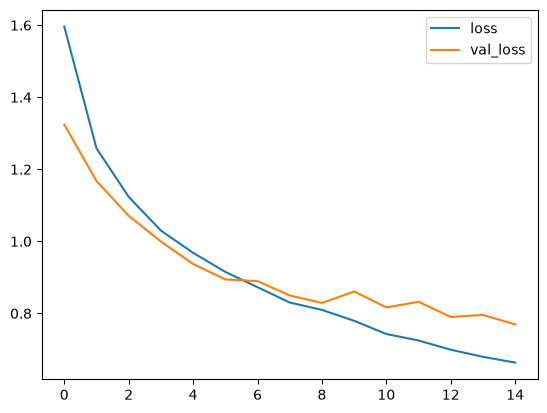

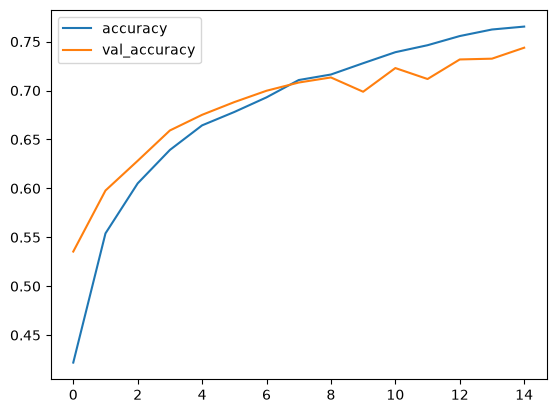

In [ ]:
losses_flip = pd.DataFrame(history_flip.history)

losses_flip[["loss", "val_loss"]].plot()

losses_flip[["accuracy", "val_accuracy"]].plot()

plt.show()

# Experiment 04: Batch Normalization


In [135]:
# Reproducibility
tf.keras.utils.set_random_seed(42)

bn_model = Sequential([
    Input(shape=(32, 32, 3)),

    RandomFlip("horizontal"),

    Conv2D(32, (4, 4)),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (4, 4)),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(256, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])
bn_model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])
bn_model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_11 (RandomFlip)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_45 (Conv2D)              │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 29, 29, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 29, 29, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_46 (Conv2D)              │ (None, 11, 11, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 256)            │       409,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 447,210 (1.71 MB)

 Trainable params: 447,018 (1.71 MB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
history_bn = bn_model.fit(
    x_fit,
    y_fit,
    epochs=15,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stop]
)

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - accuracy: 0.4495 - loss: 1.5304 - val_accuracy: 0.4630 - val_loss: 1.4466
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.5724 - loss: 1.2039 - val_accuracy: 0.5234 - val_loss: 1.3888
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6198 - loss: 1.0751 - val_accuracy: 0.6510 - val_loss: 0.9997
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.6504 - loss: 0.9951 - val_accuracy: 0.6040 - val_loss: 1.0664
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.6705 - loss: 0.9363 - val_accuracy: 0.6790 - val_loss: 0.9027
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.6905 - loss: 0.8828 - val_accuracy: 0.5978 - val_loss: 1.1983
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.7069 - loss: 0.8390 - val_accuracy: 0.7010 - val_loss: 0.8483
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.7196 - loss: 0.8050 - 

In [35]:
bn_val_loss, bn_val_acc = bn_model.evaluate(x_val,y_val,verbose=0)

print("Experiment 03 - Dropout + RandomFlip")
print("Validation Accuracy: 73.08%")
print("Validation Loss: 0.7911")

print("\nExperiment 04 - BatchNormalization")
print(f"Validation Accuracy: {bn_val_acc * 100:.2f}%")
print(f"Validation Loss: {bn_val_loss:.4f}")

best_epoch_bn = np.argmin(history_bn.history["val_loss"]) + 1
print("Best Epoch:", best_epoch_bn)


Experiment 03 - Dropout + RandomFlip
Validation Accuracy: 73.08%
Validation Loss: 0.7911

Experiment 04 - BatchNormalization
Validation Accuracy: 71.56%
Validation Loss: 0.8077
Best Epoch: 9


<Axes: >

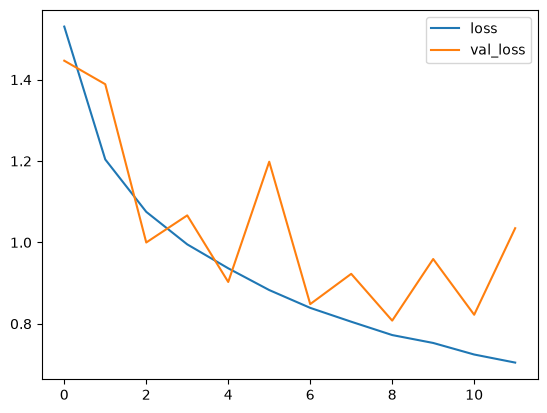

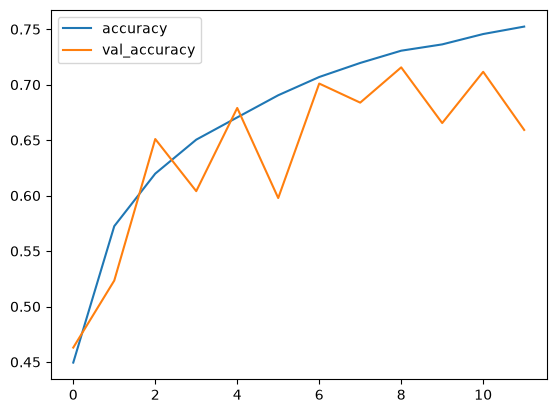

In [ ]:
losses_bn = pd.DataFrame(history_bn.history)

losses_bn[["loss", "val_loss"]].plot()

losses_bn[["accuracy", "val_accuracy"]].plot()

# Experiment 05 - RandomTranslation epochs=30

In [136]:
tf.keras.utils.set_random_seed(42)

translation_model = Sequential([
    Input(shape=(32, 32, 3)),

    RandomFlip("horizontal"),
    RandomTranslation(height_factor=0.1,width_factor=0.1,fill_mode="reflect"),

    Conv2D(32, (4, 4), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (4, 4), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(256, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])
translation_model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])
translation_model.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_12 (RandomFlip)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_7            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_47 (Conv2D)              │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_48 (Conv2D)              │ (None, 11, 11, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 256)            │       409,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 446,826 (1.70 MB)

 Trainable params: 446,826 (1.70 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
history_translation = translation_model.fit(
    x_fit,
    y_fit,
    epochs=30,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stop]
)


Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.3910 - loss: 1.6710 - val_accuracy: 0.5142 - val_loss: 1.3422
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.5099 - loss: 1.3646 - val_accuracy: 0.6052 - val_loss: 1.1418
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.5579 - loss: 1.2439 - val_accuracy: 0.6210 - val_loss: 1.0727
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.5860 - loss: 1.1674 - val_accuracy: 0.6534 - val_loss: 0.9896
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.6054 - loss: 1.1142 - val_accuracy: 0.6632 - val_loss: 0.9591
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.6246 - loss: 1.0720 - val_accuracy: 0.6608 - val_loss: 0.9668
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.6329 - loss: 1.0490 - val_accuracy: 0.6854 - val_loss: 0.9099
Epoch 8/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.6433 - loss: 1.0116 - val_accu

In [41]:
translation_val_loss, translation_val_acc = translation_model.evaluate(x_val,y_val,verbose=0)

best_epoch = np.argmin(
    history_translation.history["val_loss"]
) + 1

print("Experiment 03 - Dropout + RandomFlip")
print("Validation Accuracy: 73.08%")
print("Validation Loss: 0.7911")

print("\nExperiment 05 - RandomTranslation")
print(f"Validation Accuracy: {translation_val_acc * 100:.2f}%")
print(f"Validation Loss: {translation_val_loss:.4f}")
print("Best Epoch:", best_epoch)


Experiment 03 - Dropout + RandomFlip
Validation Accuracy: 73.08%
Validation Loss: 0.7911

Experiment 05 - RandomTranslation
Validation Accuracy: 75.20%
Validation Loss: 0.7098
Best Epoch: 28


<Axes: >

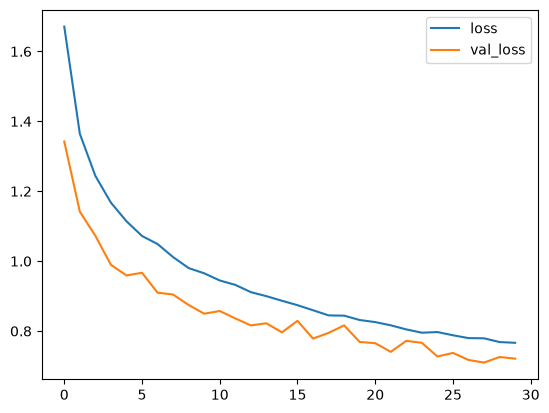

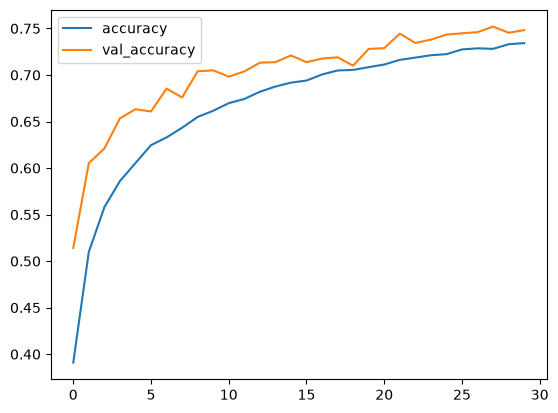

In [42]:
losses_translation = pd.DataFrame(history_translation.history)

losses_translation[["loss", "val_loss"]].plot()

losses_translation[["accuracy", "val_accuracy"]].plot()


# Experiment 06 - Dropout + RandomFlip  epochs=30

In [137]:
flip_model = Sequential([
    Input(shape=(32, 32, 3)),

    RandomFlip("horizontal"),

    Conv2D(32, (4, 4), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (4, 4), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(256, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

flip_model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

flip_model.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_13 (RandomFlip)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_49 (Conv2D)              │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_50 (Conv2D)              │ (None, 11, 11, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_12 (Flatten)            │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 256)            │       409,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 446,826 (1.70 MB)

 Trainable params: 446,826 (1.70 MB)

 Non-trainable params: 0 (0.00 B)

In [46]:
history_flip = flip_model.fit(
    x_fit,
    y_fit,
    epochs=30,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stop]
)

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.4247 - loss: 1.5813 - val_accuracy: 0.5118 - val_loss: 1.3678
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5496 - loss: 1.2639 - val_accuracy: 0.5932 - val_loss: 1.1635
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.6050 - loss: 1.1272 - val_accuracy: 0.6268 - val_loss: 1.0704
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6393 - loss: 1.0384 - val_accuracy: 0.6462 - val_loss: 1.0201
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6611 - loss: 0.9707 - val_accuracy: 0.6492 - val_loss: 1.0239
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6816 - loss: 0.9116 - val_accuracy: 0.6870 - val_loss: 0.9173
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6981 - loss: 0.8695 - val_accuracy: 0.6950 - val_loss: 0.8878
Epoch 8/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7103 - loss: 0.8329 - val_accu

In [ ]:
flip_val_loss, flip_val_acc = flip_model.evaluate(
    x_val,
    y_val,
    verbose=0
)

print("\nExperiment 03 - Dropout + RandomFlip")
print(f"Validation Accuracy: {flip_val_acc * 100:.2f}%")
print(f"Validation Loss: {flip_val_loss:.4f}")


Experiment 03 - Dropout + RandomFlip
Validation Accuracy: 72.26%
Validation Loss: 0.8217


<Axes: >

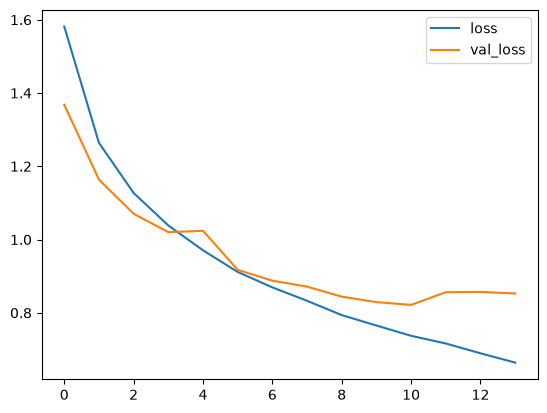

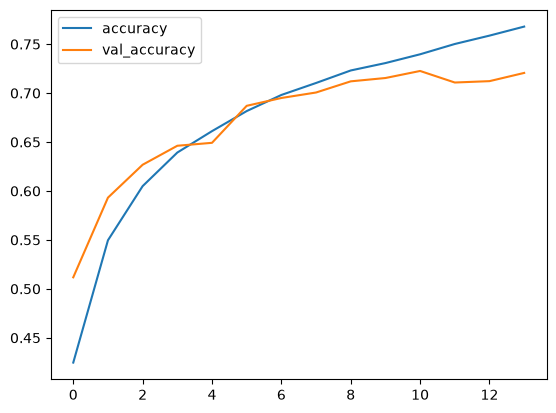

In [138]:
losses_flip = pd.DataFrame(history_flip.history)

losses_flip[["loss", "val_loss"]].plot()

losses_flip[["accuracy", "val_accuracy"]].plot()

# Experiment 07-RandomTranslation (epochs=30 + 3×3 Kernels) 

In [49]:
tf.keras.utils.set_random_seed(42)

model_07 = Sequential([
    Input(shape=(32, 32, 3)),

    RandomFlip("horizontal"),

    RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="reflect"
    ),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(256, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

model_07.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_07.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_4 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 612,042 (2.33 MB)

 Trainable params: 612,042 (2.33 MB)

 Non-trainable params: 0 (0.00 B)

In [50]:
history_07 = model_07.fit(
    x_fit,
    y_fit,
    epochs=30,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stop]
)

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.4094 - loss: 1.6181 - val_accuracy: 0.5224 - val_loss: 1.3160
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.5293 - loss: 1.3168 - val_accuracy: 0.5942 - val_loss: 1.1236
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.5771 - loss: 1.1977 - val_accuracy: 0.6390 - val_loss: 1.0193
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.6000 - loss: 1.1309 - val_accuracy: 0.6580 - val_loss: 0.9774
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.6206 - loss: 1.0801 - val_accuracy: 0.6752 - val_loss: 0.9200
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6341 - loss: 1.0377 - val_accuracy: 0.6822 - val_loss: 0.9002
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.6443 - loss: 1.0142 - val_accuracy: 0.6842 - val_loss: 0.9053
Epoch 8/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.6525 - loss: 0.9885 - val_ac

In [51]:
val_loss_07, val_acc_07 = model_07.evaluate(x_val, y_val,verbose=0)

best_epoch_07 = np.argmin(history_07.history["val_loss"]) + 1

print("Experiment 07 - CNN 3x3")
print(f"Validation Accuracy: {val_acc_07 * 100:.2f}%")
print(f"Validation Loss: {val_loss_07:.4f}")
print(f"Best Epoch: {best_epoch_07}")


Experiment 07 - CNN 3x3
Validation Accuracy: 76.78%
Validation Loss: 0.6842
Best Epoch: 27


<Axes: >

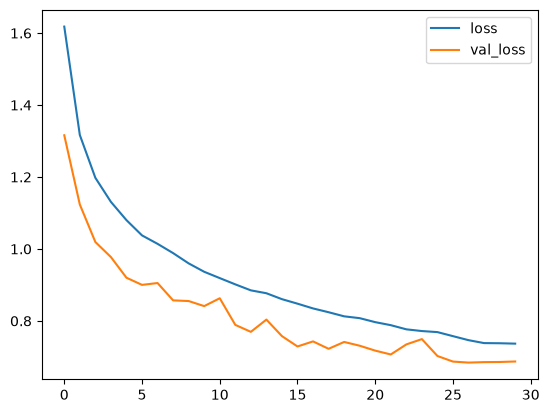

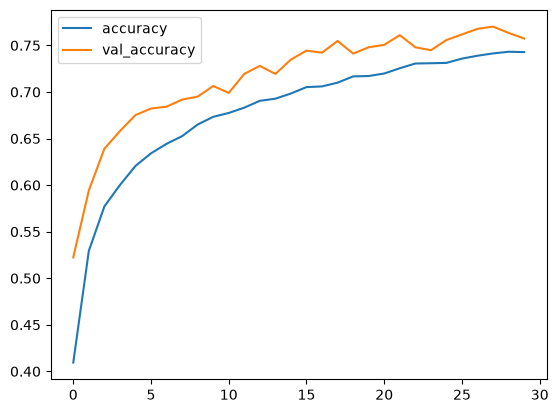

In [52]:
losses_07 = pd.DataFrame(history_07.history)

losses_07[["loss", "val_loss"]].plot()

losses_07[["accuracy", "val_accuracy"]].plot()


In [53]:
# Create directories
Path("models").mkdir(parents=True, exist_ok=True)
Path("results").mkdir(parents=True, exist_ok=True)

# Save best model
model_07.save("models/cnn_3x3_best.keras")

# Save training history
results_07 = pd.DataFrame(history_07.history)
results_07.index = results_07.index + 1
results_07.index.name = "Epoch"

results_07.to_csv("results/experiment_06_history.csv")

print("Experiment 06 saved successfully!")


Experiment 06 saved successfully!


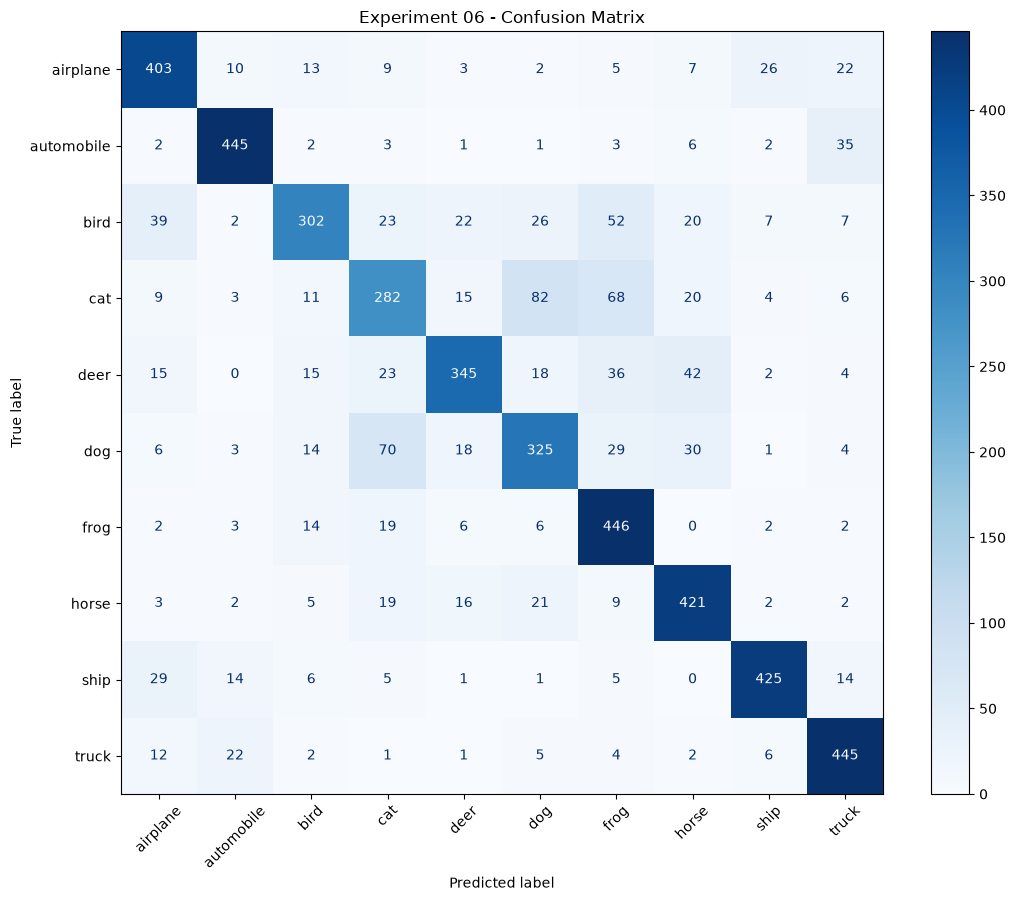

In [139]:
# Predict on Validation Set
y_pred_probs = model_07.predict(
    x_val,
    batch_size=64,
    verbose=0
)

# Convert predictions to class labels
y_pred = np.argmax(y_pred_probs, axis=1)

# Convert One-Hot labels to integers
y_true = np.argmax(y_val, axis=1)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

# Plot
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(11, 9))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)

plt.title("Experiment 06 - Confusion Matrix")
plt.tight_layout()
plt.show()


# Experiment 08 – Deeper CNN

In [ ]:
tf.keras.utils.set_random_seed(42)

model_08 = Sequential([
    Input(shape=(32, 32, 3)),

    RandomFlip("horizontal"),
    RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="reflect"
    ),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

model_08.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

model_08.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_5 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_2            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402,986 (1.54 MB)

 Trainable params: 402,986 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

In [56]:
history_08 = model_08.fit(
    x_fit,
    y_fit,
    epochs=30,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stop]
)

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 26s 34ms/step - accuracy: 0.3646 - loss: 1.7154 - val_accuracy: 0.4984 - val_loss: 1.3519
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 36ms/step - accuracy: 0.5187 - loss: 1.3296 - val_accuracy: 0.6232 - val_loss: 1.0457
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 34ms/step - accuracy: 0.5947 - loss: 1.1443 - val_accuracy: 0.6722 - val_loss: 0.9118
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.6420 - loss: 1.0147 - val_accuracy: 0.6864 - val_loss: 0.8816
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 36ms/step - accuracy: 0.6766 - loss: 0.9241 - val_accuracy: 0.7252 - val_loss: 0.8058
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 32ms/step - accuracy: 0.6981 - loss: 0.8644 - val_accuracy: 0.7470 - val_loss: 0.7189
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 36ms/step - accuracy: 0.7174 - loss: 0.8168 - val_accuracy: 0.7656 - val_loss: 0.6754
Epoch 8/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 35ms/step - accuracy: 0.7320 - loss: 0.7702 - 

In [57]:
val_loss_08, val_acc_08 = model_08.evaluate(x_val,y_val,verbose=0)

best_epoch_08 = np.argmin(history_08.history["val_loss"]) + 1

print("Experiment 08 - Deeper CNN")
print(f"Validation Accuracy: {val_acc_08 * 100:.2f}%")
print(f"Validation Loss: {val_loss_08:.4f}")
print(f"Best Epoch: {best_epoch_08}")
print(f"Epochs Completed: {len(history_08.history['loss'])}")

Experiment 08 - Deeper CNN
Validation Accuracy: 79.68%
Validation Loss: 0.5950
Best Epoch: 12
Epochs Completed: 15


<Axes: >

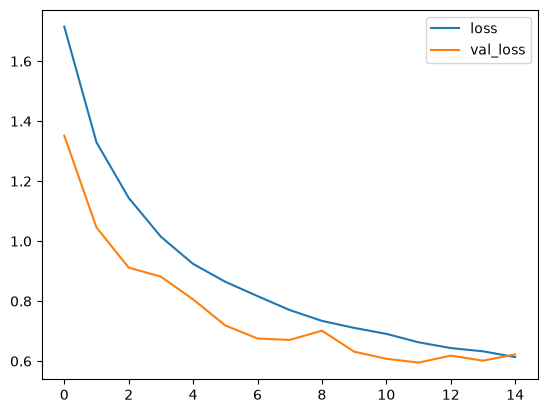

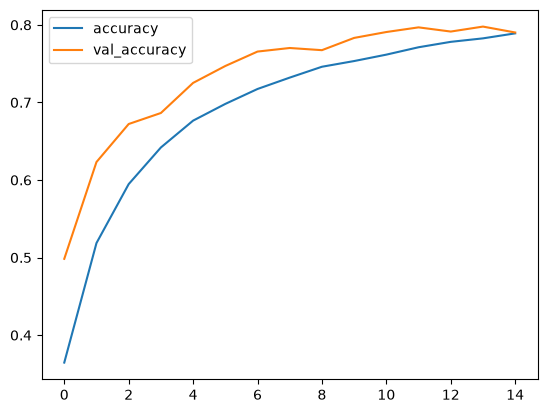

In [58]:
losses_08 = pd.DataFrame(history_08.history)

losses_08[["loss", "val_loss"]].plot()

losses_08[["accuracy", "val_accuracy"]].plot()


In [59]:
Path("models").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

# Save Experiment 07
model_07.save("models/cnn_deeper_best.keras")

# Save training history
results_08 = pd.DataFrame(history_08.history)
results_08.index = results_08.index + 1
results_08.index.name = "Epoch"

results_08.to_csv("results/experiment_08_history.csv")

print("Experiment 08 saved successfully!")


Experiment 08 saved successfully!


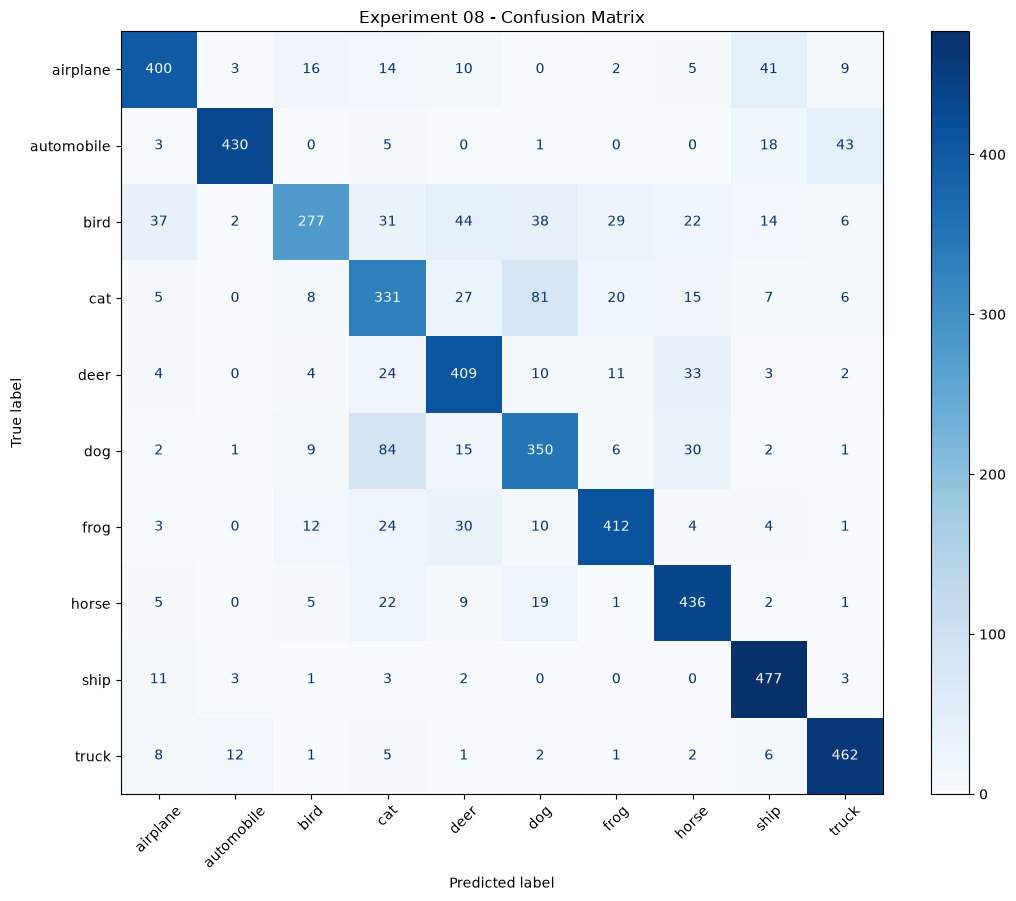

Experiment 08 - Classification Report
              precision    recall  f1-score   support

    airplane       0.84      0.80      0.82       500
  automobile       0.95      0.86      0.90       500
        bird       0.83      0.55      0.67       500
         cat       0.61      0.66      0.63       500
        deer       0.75      0.82      0.78       500
         dog       0.68      0.70      0.69       500
        frog       0.85      0.82      0.84       500
       horse       0.80      0.87      0.83       500
        ship       0.83      0.95      0.89       500
       truck       0.87      0.92      0.89       500

    accuracy                           0.80      5000
   macro avg       0.80      0.80      0.79      5000
weighted avg       0.80      0.80      0.79      5000



In [60]:
# Predictions on Validation Set
y_pred = np.argmax(
    model_08.predict(x_val, batch_size=64, verbose=0),
    axis=1
)

y_true = np.argmax(y_val, axis=1)

# Confusion Matrix
cm_08 = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_08,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(11, 9))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Experiment 08 - Confusion Matrix")
plt.tight_layout()
plt.show()

# Classification Report
print("Experiment 08 - Classification Report")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))


Cat classified as Dog: 81


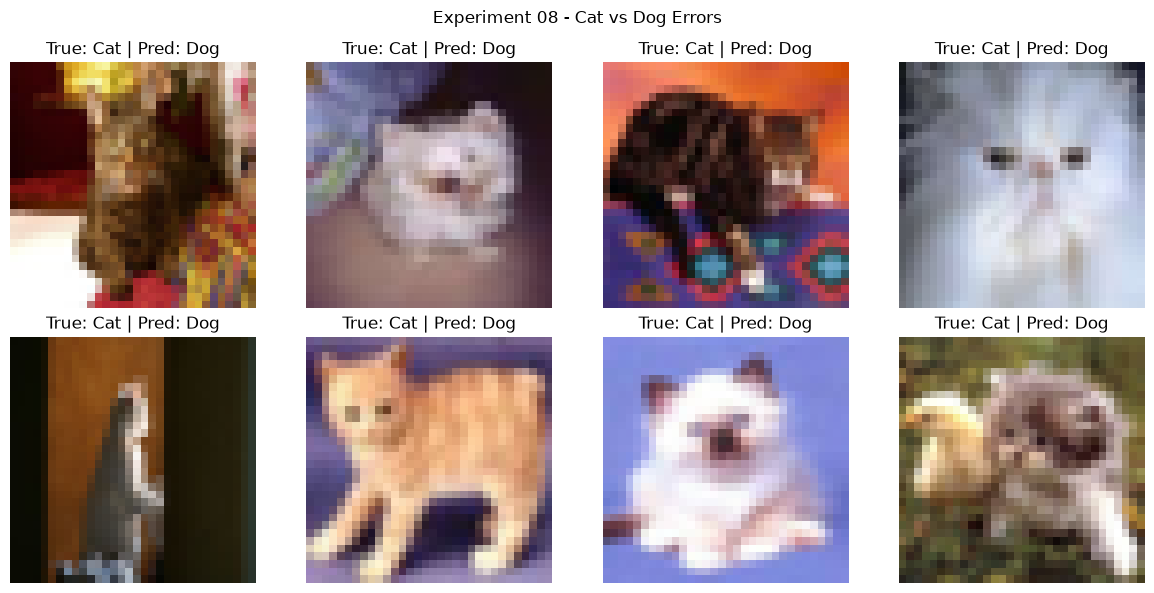

In [61]:
# Find cats incorrectly classified as dogs
error_indices = np.where(
    (y_true == 3) & (y_pred == 5)
)[0]

print("Cat classified as Dog:", len(error_indices))

# Display 8 misclassified images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, idx in zip(axes.flat, error_indices[:8]):
    ax.imshow(x_val[idx])
    ax.set_title("True: Cat | Pred: Dog")
    ax.axis("off")

plt.suptitle("Experiment 08 - Cat vs Dog Errors")
plt.tight_layout()
plt.show()


# Experiment - 9  ReduceLROnPlateau

In [62]:

tf.keras.utils.set_random_seed(42)

# Create a fresh model with Experiment 08 architecture
model_09 = tf.keras.models.clone_model(model_08)

model_09.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Reduce Learning Rate when validation loss stops improving
reduce_lr_09 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

model_09.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_5 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_2            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402,986 (1.54 MB)

 Trainable params: 402,986 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

In [63]:
early_stop_09 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history_09 = model_09.fit(
    x_fit,
    y_fit,
    epochs=30,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[reduce_lr_09, early_stop_09]
)


Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 34ms/step - accuracy: 0.3646 - loss: 1.7154 - val_accuracy: 0.4984 - val_loss: 1.3519 - learning_rate: 0.0010
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 34ms/step - accuracy: 0.5187 - loss: 1.3296 - val_accuracy: 0.6232 - val_loss: 1.0457 - learning_rate: 0.0010
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 33ms/step - accuracy: 0.5947 - loss: 1.1443 - val_accuracy: 0.6722 - val_loss: 0.9118 - learning_rate: 0.0010
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 34ms/step - accuracy: 0.6420 - loss: 1.0147 - val_accuracy: 0.6864 - val_loss: 0.8816 - learning_rate: 0.0010
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 33ms/step - accuracy: 0.6766 - loss: 0.9241 - val_accuracy: 0.7252 - val_loss: 0.8058 - learning_rate: 0.0010
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 33ms/step - accuracy: 0.6981 - loss: 0.8644 - val_accuracy: 0.7470 - val_loss: 0.7189 - learning_rate: 0.0010
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 34ms/step - accuracy: 0.7174 - l

In [64]:
val_loss_09, val_acc_09 = model_09.evaluate(x_val,y_val,verbose=0)

best_epoch_09 = np.argmin(history_09.history["val_loss"]) + 1

print("Experiment 09 - ReduceLROnPlateau")
print(f"Validation Accuracy: {val_acc_09 * 100:.2f}%")
print(f"Validation Loss: {val_loss_09:.4f}")
print(f"Best Epoch: {best_epoch_09}")
print(f"Epochs Completed: {len(history_09.history['loss'])}")


Experiment 09 - ReduceLROnPlateau
Validation Accuracy: 84.96%
Validation Loss: 0.4652
Best Epoch: 30
Epochs Completed: 30


<Axes: >

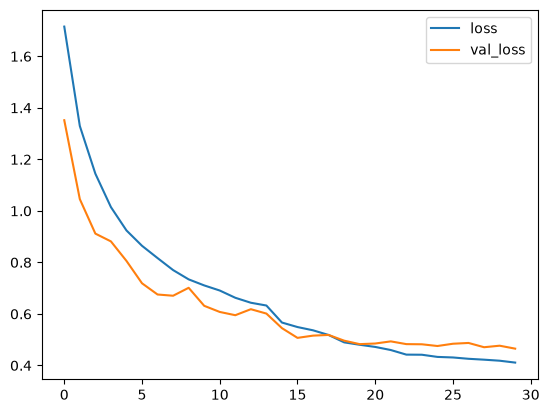

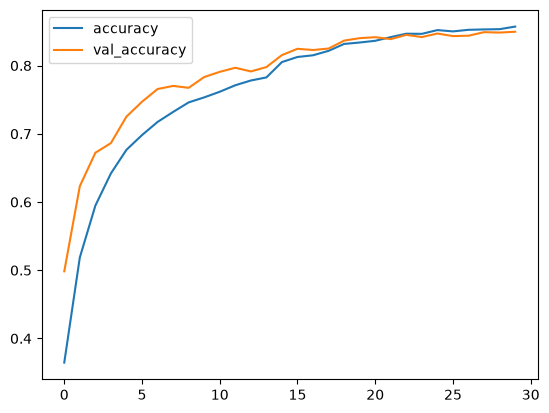

In [65]:
losses_09 = pd.DataFrame(history_09.history)

losses_09[["loss", "val_loss"]].plot()

losses_09[["accuracy", "val_accuracy"]].plot()

In [66]:
Path("models").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

# Save Experiment 09
model_09.save("models/cnn_best_09.keras")

# Save Training History
results_09 = pd.DataFrame(history_09.history)

results_09.index = results_09.index + 1
results_09.index.name = "Epoch"

results_09.to_csv("results/experiment_09_history.csv")

print("Experiment 09 saved successfully!")

Experiment 09 saved successfully!


Experiment 09 - Classification Report
              precision    recall  f1-score   support

    airplane       0.86      0.88      0.87       500
  automobile       0.93      0.95      0.94       500
        bird       0.84      0.72      0.77       500
         cat       0.73      0.68      0.70       500
        deer       0.85      0.85      0.85       500
         dog       0.78      0.74      0.76       500
        frog       0.82      0.90      0.86       500
       horse       0.85      0.90      0.87       500
        ship       0.93      0.94      0.94       500
       truck       0.91      0.94      0.92       500

    accuracy                           0.85      5000
   macro avg       0.85      0.85      0.85      5000
weighted avg       0.85      0.85      0.85      5000



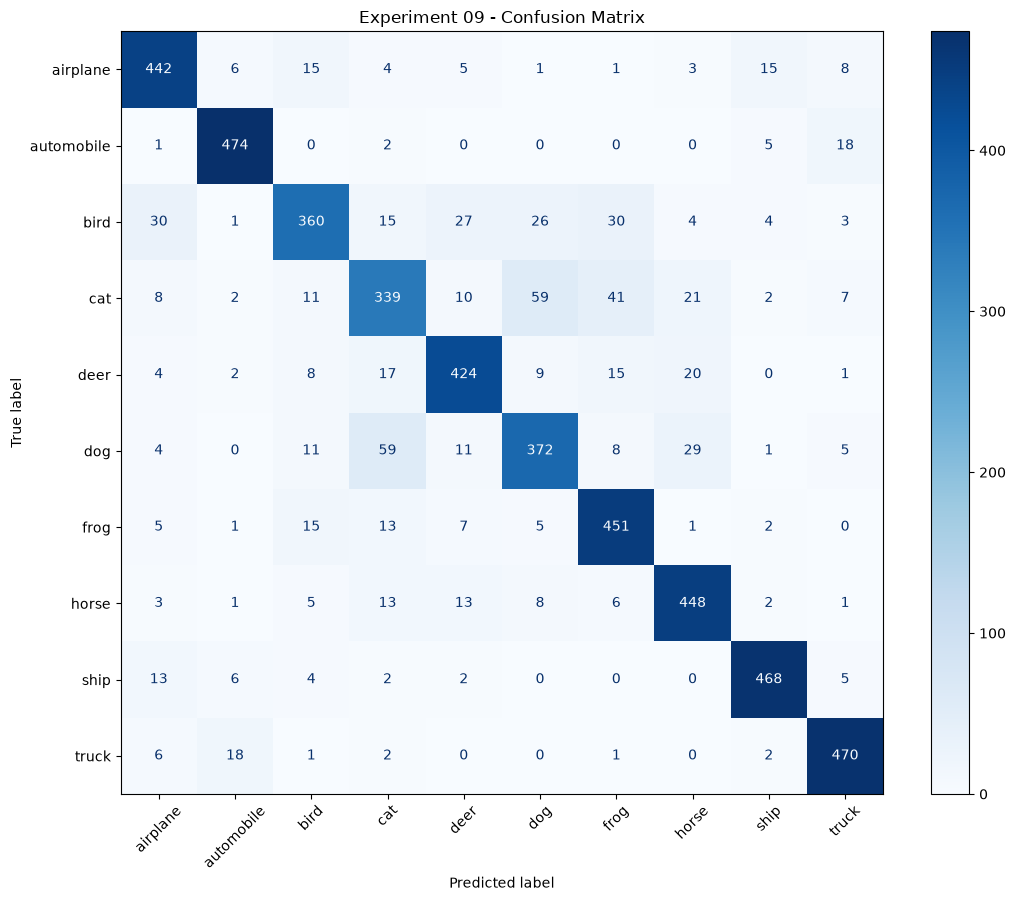

In [67]:
# Predictions on Validation Set
y_pred_09 = np.argmax(model_09.predict(x_val, batch_size=64, verbose=0),axis=1)

y_true_09 = np.argmax(y_val, axis=1)

# Confusion Matrix
cm_09 = confusion_matrix(y_true_09, y_pred_09)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_09,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(11, 9))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Experiment 09 - Confusion Matrix")
plt.tight_layout()

# Classification Report
print("Experiment 09 - Classification Report")

print(classification_report(
    y_true_09,
    y_pred_09,
    target_names=class_names
))


# Experiment 10 


For the Experiment 09 architecture, we added a second Conv2D(128) layer to the final convolutional block

In [68]:
tf.keras.utils.set_random_seed(42)

model_10 = Sequential([
    Input(shape=(32, 32, 3)),

    RandomFlip("horizontal"),
    RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="reflect"
    ),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

model_10.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_10.summary()


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_6 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_3            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 550,570 (2.10 MB)

 Trainable params: 550,570 (2.10 MB)

 Non-trainable params: 0 (0.00 B)

In [69]:
# Learning Rate Scheduler
reduce_lr_10 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

# Early Stopping
early_stop_10 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

# Training
history_10 = model_10.fit(
    x_fit,
    y_fit,
    epochs=30,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[reduce_lr_10, early_stop_10]
)

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 42ms/step - accuracy: 0.3646 - loss: 1.7073 - val_accuracy: 0.5022 - val_loss: 1.3372 - learning_rate: 0.0010
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5158 - loss: 1.3343 - val_accuracy: 0.6204 - val_loss: 1.0589 - learning_rate: 0.0010
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - accuracy: 0.5957 - loss: 1.1355 - val_accuracy: 0.6674 - val_loss: 0.9083 - learning_rate: 0.0010
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.6546 - loss: 0.9900 - val_accuracy: 0.7074 - val_loss: 0.8183 - learning_rate: 0.0010
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 40ms/step - accuracy: 0.6877 - loss: 0.8940 - val_accuracy: 0.7416 - val_loss: 0.7479 - learning_rate: 0.0010
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.7126 - loss: 0.8322 - val_accuracy: 0.7476 - val_loss: 0.7221 - learning_rate: 0.0010
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.7301 - l

In [70]:
val_loss_10, val_acc_10 = model_10.evaluate(x_val,y_val,verbose=0)

best_epoch_10 = np.argmin(
    history_10.history["val_loss"]
) + 1

print("Experiment 10 - Deeper CNN")

print(f"Validation Accuracy: {val_acc_10 * 100:.2f}%")
print(f"Validation Loss: {val_loss_10:.4f}")
print(f"Best Epoch: {best_epoch_10}")
print(f"Epochs Completed: {len(history_10.history['loss'])}")


Experiment 10 - Deeper CNN
Validation Accuracy: 84.70%
Validation Loss: 0.4914
Best Epoch: 30
Epochs Completed: 30


<Axes: >

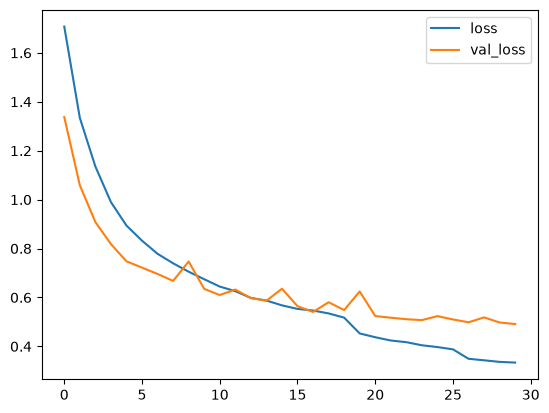

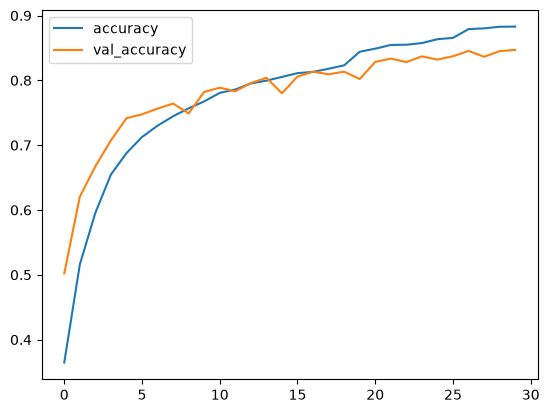

In [71]:
losses_10 = pd.DataFrame(history_10.history)

losses_10[["loss", "val_loss"]].plot()

losses_10[["accuracy", "val_accuracy"]].plot()

In [72]:
Path("models").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

# Save Experiment 10
model_10.save("models/cnn_best_10.keras")

# Save Training History
results_10 = pd.DataFrame(history_10.history)

results_10.index = results_10.index + 1
results_10.index.name = "Epoch"

results_10.to_csv("results/experiment_10_history.csv")

print("Experiment 10 saved successfully!")


Experiment 10 saved successfully!


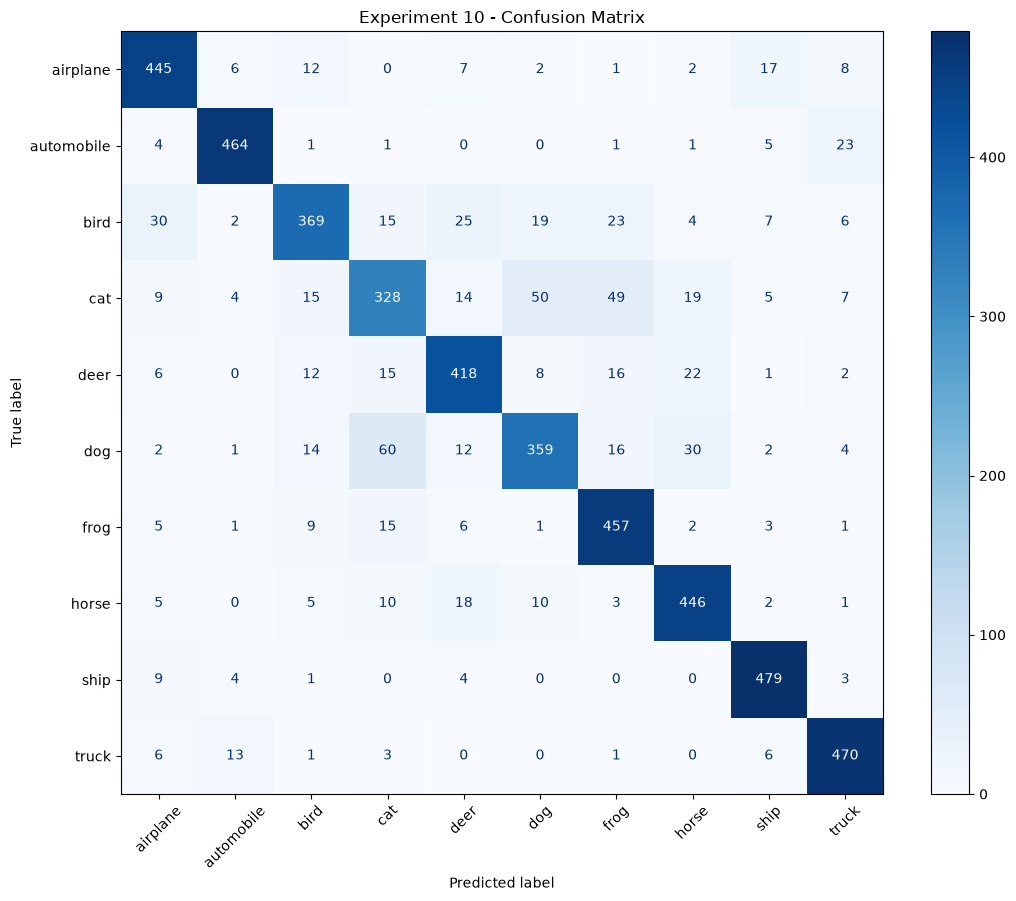

Experiment 10 - Classification Report
              precision    recall  f1-score   support

    airplane       0.85      0.89      0.87       500
  automobile       0.94      0.93      0.93       500
        bird       0.84      0.74      0.79       500
         cat       0.73      0.66      0.69       500
        deer       0.83      0.84      0.83       500
         dog       0.80      0.72      0.76       500
        frog       0.81      0.91      0.86       500
       horse       0.85      0.89      0.87       500
        ship       0.91      0.96      0.93       500
       truck       0.90      0.94      0.92       500

    accuracy                           0.85      5000
   macro avg       0.85      0.85      0.84      5000
weighted avg       0.85      0.85      0.84      5000

Validation Accuracy: 84.70%


In [73]:
# Predictions on Validation Set
y_pred_10 = np.argmax(
    model_10.predict(x_val, batch_size=64, verbose=0),
    axis=1
)

y_true_10 = np.argmax(y_val, axis=1)

# Confusion Matrix
cm_10 = confusion_matrix(
    y_true_10,
    y_pred_10,
    labels=np.arange(10)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_10,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(11, 9))

disp.plot(ax=ax,cmap="Blues",xticks_rotation=45)

plt.title("Experiment 10 - Confusion Matrix")
plt.tight_layout()

Path("results").mkdir(exist_ok=True)

plt.savefig(
    "results/experiment_10_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Classification Report
print("Experiment 10 - Classification Report")

print(classification_report(
    y_true_10,
    y_pred_10,
    target_names=class_names
))

# Check overall accuracy
print(
    "Validation Accuracy:",
    f"{np.trace(cm_10) / cm_10.sum() * 100:.2f}%"
)


# Experiment 11

The architecture for Experiment 10 contains 6 Conv2D layers, with only one layer replaced:
- We removed `Flatten()`.
- We added `GlobalAveragePooling2D()`.
- We kept `Dense(128)`, `Dropout(0.3)`, and the rest of the architecture.

In [ ]:
tf.keras.utils.set_random_seed(42)

model_11 = Sequential([
    Input(shape=(32, 32, 3)),

    RandomFlip("horizontal"),
    RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="reflect"
    ),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

model_11.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_11.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_8 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_5            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 304,810 (1.16 MB)

 Trainable params: 304,810 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
reduce_lr_11 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

early_stop_11 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history_11 = model_11.fit(
    x_fit,
    y_fit,
    epochs=30,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[reduce_lr_11, early_stop_11]
)

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 39s 51ms/step - accuracy: 0.3144 - loss: 1.7957 - val_accuracy: 0.4128 - val_loss: 1.6267 - learning_rate: 0.0010
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 37s 45ms/step - accuracy: 0.4766 - loss: 1.4182 - val_accuracy: 0.5260 - val_loss: 1.2861 - learning_rate: 0.0010
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 39s 42ms/step - accuracy: 0.5575 - loss: 1.2295 - val_accuracy: 0.6184 - val_loss: 1.0309 - learning_rate: 0.0010
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 42ms/step - accuracy: 0.6089 - loss: 1.1004 - val_accuracy: 0.6316 - val_loss: 1.0259 - learning_rate: 0.0010
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 43ms/step - accuracy: 0.6469 - loss: 0.9973 - val_accuracy: 0.6712 - val_loss: 0.9205 - learning_rate: 0.0010
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.6776 - loss: 0.9143 - val_accuracy: 0.7070 - val_loss: 0.8557 - learning_rate: 0.0010
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - accuracy: 0.7005 - l

In [ ]:
val_loss_11, val_acc_11 = model_11.evaluate(x_val,y_val,verbose=0)

best_epoch_11 = np.argmin(history_11.history["val_loss"]) + 1

print("Experiment 11 - GlobalAveragePooling2D")
print(f"Validation Accuracy: {val_acc_11 * 100:.2f}%")
print(f"Validation Loss: {val_loss_11:.4f}")
print(f"Best Epoch: {best_epoch_11}")
print(f"Epochs Completed: {len(history_11.history['loss'])}")

Experiment 11 - GlobalAveragePooling2D
Validation Accuracy: 84.84%
Validation Loss: 0.4828
Best Epoch: 30
Epochs Completed: 30


<Axes: >

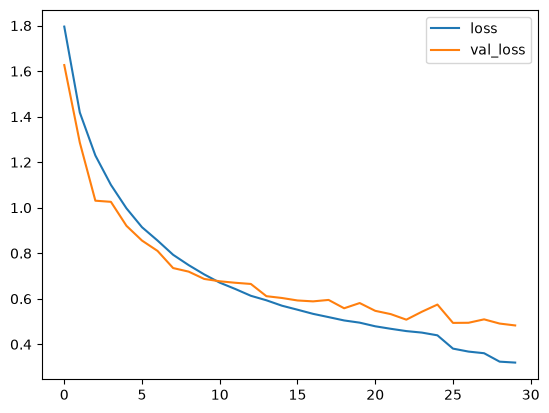

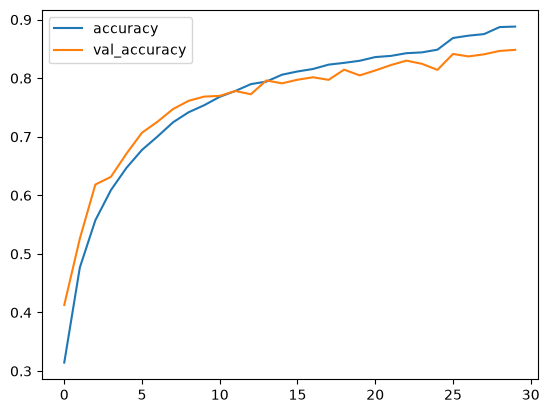

In [86]:
losses_11 = pd.DataFrame(history_11.history)

losses_11[["loss", "val_loss"]].plot()

losses_11[["accuracy", "val_accuracy"]].plot()

In [ ]:
Path("models").mkdir(exist_ok=True)

model_11.save("models/exp11_epoch30.keras")

print("Experiment 11 - Epoch 30 saved!")

Experiment 11 - Epoch 30 saved!


In [ ]:
reduce_lr_11_extra = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

early_stop_11_extra = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_11_extra = model_11.fit(
    x_fit,
    y_fit,
    initial_epoch=30,
    epochs=45,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[reduce_lr_11_extra, early_stop_11_extra]
)

val_loss_11_extra, val_acc_11_extra = model_11.evaluate(
    x_val, y_val, verbose=0
)

print("Experiment 11 - Extended")
print(f"Validation Accuracy: {val_acc_11_extra * 100:.2f}%")
print(f"Validation Loss: {val_loss_11_extra:.4f}")

Epoch 31/45
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.8932 - loss: 0.3081 - val_accuracy: 0.8456 - val_loss: 0.4874 - learning_rate: 2.5000e-04
Epoch 32/45
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 42ms/step - accuracy: 0.8946 - loss: 0.3028 - val_accuracy: 0.8554 - val_loss: 0.4545 - learning_rate: 2.5000e-04
Epoch 33/45
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - accuracy: 0.8949 - loss: 0.2997 - val_accuracy: 0.8518 - val_loss: 0.4811 - learning_rate: 2.5000e-04
Epoch 34/45
702/704 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8974 - loss: 0.2933
Epoch 34: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 40ms/step - accuracy: 0.8974 - loss: 0.2933 - val_accuracy: 0.8544 - val_loss: 0.4850 - learning_rate: 2.5000e-04
Epoch 35/45
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.9003 - loss: 0.2816 - val_accuracy: 0.8576 - val_loss: 0.4740 - learning_rate: 1.2500e-04
Epoch 36/45
702/704 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/ste

In [89]:
Path("models").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

# Save improved Experiment 11
model_11.save("models/exp11_extended_best.keras")

# Combine training histories
combined_history_11 = pd.DataFrame({
    key: history_11.history[key] +
         history_11_extra.history[key]
    for key in history_11.history
})

combined_history_11.index = range(
    1, len(combined_history_11) + 1
)
combined_history_11.index.name = "Epoch"

combined_history_11.to_csv(
    "results/experiment_11_extended_history.csv"
)

print("Experiment 11 - Extended saved successfully!")


Experiment 11 - Extended saved successfully!


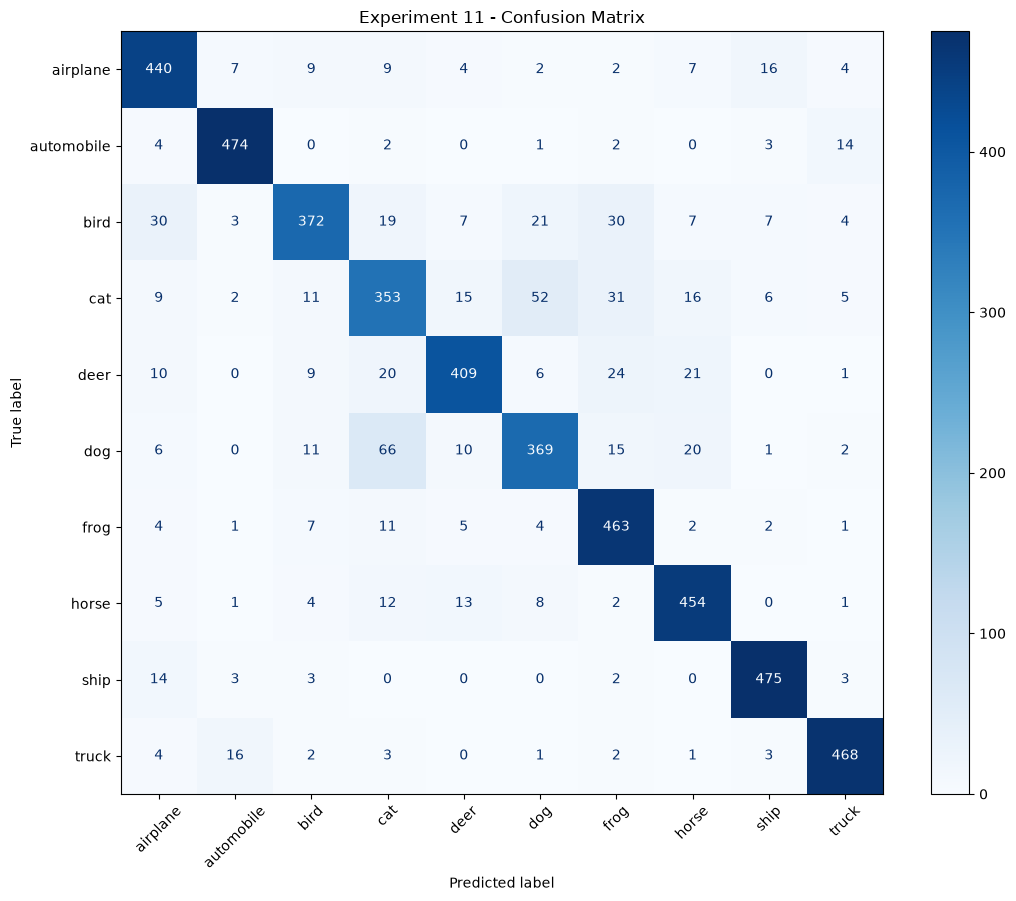

Experiment 11 - Classification Report
              precision    recall  f1-score   support

    airplane      0.837     0.880     0.858       500
  automobile      0.935     0.948     0.941       500
        bird      0.869     0.744     0.802       500
         cat      0.713     0.706     0.710       500
        deer      0.883     0.818     0.849       500
         dog      0.795     0.738     0.766       500
        frog      0.808     0.926     0.863       500
       horse      0.860     0.908     0.883       500
        ship      0.926     0.950     0.938       500
       truck      0.930     0.936     0.933       500

    accuracy                          0.855      5000
   macro avg      0.856     0.855     0.854      5000
weighted avg      0.856     0.855     0.854      5000

Validation Accuracy: 85.54%


In [ ]:
# Prediction on Validation Set
y_pred_11 = np.argmax(
    model_11.predict(x_val, batch_size=64, verbose=0),
    axis=1
)

y_true_11 = np.argmax(y_val, axis=1)

# Confusion Matrix
cm_11 = confusion_matrix(
    y_true_11,
    y_pred_11,
    labels=np.arange(10)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_11,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(11, 9))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Experiment 11 - Confusion Matrix")
plt.tight_layout()

Path("results").mkdir(exist_ok=True)

plt.show()

# Classification Report
report_11 = classification_report(
    y_true_11,
    y_pred_11,
    target_names=class_names,
    digits=3
)

print("Experiment 11 - Classification Report")
print(report_11)

# Save report for GitHub
Path("results/experiment_11_report.txt").write_text(
    report_11,
    encoding="utf-8"
)

print("Validation Accuracy:",
      f"{np.trace(cm_11) / cm_11.sum() * 100:.2f}%")


# Experiment 12 – RandomContrast Data Augmentation.

This experiment adopts the best architecture from Experiment 11, and we have incorporated a new technique to improve the model's ability to handle variations in lighting and contrast within the images.

In [92]:
tf.keras.utils.set_random_seed(42)

model_12 = Sequential([
    Input(shape=(32, 32, 3)),

    # Data Augmentation
    RandomFlip("horizontal"),

    RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="reflect"
    ),

    RandomContrast(0.1),

    # Convolutional Block 1
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    # Convolutional Block 2
    Conv2D(64, (3, 3), activation="relu", padding="same"),
    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    # Convolutional Block 3
    Conv2D(128, (3, 3), activation="relu", padding="same"),
    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    # Classification
    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

model_12.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_12.summary()


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_9 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_6            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 32, 32, 3)      │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 304,810 (1.16 MB)

 Trainable params: 304,810 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

In [94]:
Path("models").mkdir(exist_ok=True)

# Learning Rate Scheduler
reduce_lr_12 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

# Early Stopping
early_stop_12 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Save best model automatically
checkpoint_12 = ModelCheckpoint(
    filepath="models/exp12_best.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Training
history_12 = model_12.fit(
    x_fit,
    y_fit,
    epochs=45,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[
        reduce_lr_12,
        early_stop_12,
        checkpoint_12
    ]
)


Epoch 1/45
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.3034 - loss: 1.8225
Epoch 1: val_loss improved from None to 1.49597, saving model to models/exp12_best.keras

Epoch 1: finished saving model to models/exp12_best.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 44ms/step - accuracy: 0.3034 - loss: 1.8225 - val_accuracy: 0.4336 - val_loss: 1.4960 - learning_rate: 0.0010
Epoch 2/45
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.4894 - loss: 1.3750
Epoch 2: val_loss improved from 1.49597 to 1.13758, saving model to models/exp12_best.keras

Epoch 2: finished saving model to models/exp12_best.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 46ms/step - accuracy: 0.4893 - loss: 1.3750 - val_accuracy: 0.5766 - val_loss: 1.1376 - learning_rate: 0.0010
Epoch 3/45
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.5719 - loss: 1.1860
Epoch 3: val_loss improved from 1.13758 to 0.99857, saving model to models/exp12_best.keras

Epoch 3: finished saving model to models/exp12_best.keras
704

In [95]:
val_loss_12, val_acc_12 = model_12.evaluate(x_val,y_val,verbose=0)

best_epoch_12 = np.argmin(
    history_12.history["val_loss"]
) + 1

print("Experiment 12 - RandomContrast")
print(f"Validation Accuracy: {val_acc_12 * 100:.2f}%")
print(f"Validation Loss: {val_loss_12:.4f}")
print(f"Best Epoch: {best_epoch_12}")
print(f"Epochs Completed: {len(history_12.history['loss'])}")


Experiment 12 - RandomContrast
Validation Accuracy: 84.38%
Validation Loss: 0.4710
Best Epoch: 27
Epochs Completed: 32


<Axes: >

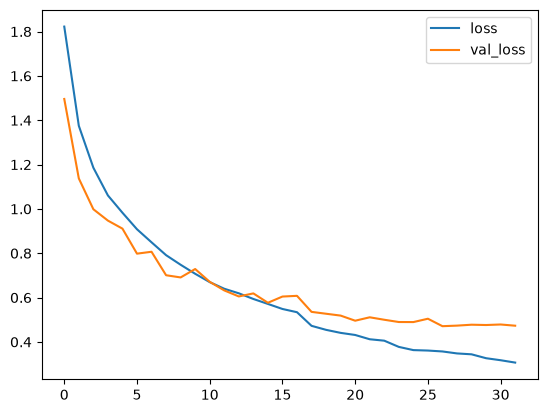

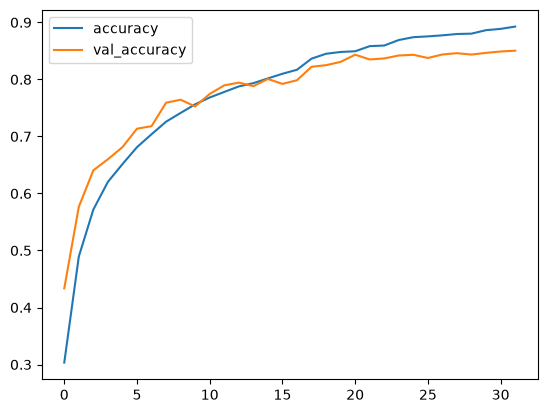

In [96]:
losses_12 = pd.DataFrame(history_12.history)

losses_12[["loss", "val_loss"]].plot()

losses_12[["accuracy", "val_accuracy"]].plot()


In [97]:
Path("results").mkdir(exist_ok=True)

results_12 = pd.DataFrame(history_12.history)

results_12.index = results_12.index + 1
results_12.index.name = "Epoch"

results_12.to_csv(
    "results/experiment_12_history.csv"
)

print("Experiment 12 results saved!")


Experiment 12 results saved!


# Comparison of categories between the two models Exp 11 vs. Exp 12

In [ ]:
model_11_best = load_model(
    "models/exp11_extended_best.keras"
)

model_12_best = load_model(
    "models/exp12_best.keras"
)

y_true = np.argmax(y_val, axis=1)

models_compare = {
    "Exp 11": model_11_best,
    "Exp 12": model_12_best
}

class_results = pd.DataFrame(index=class_names)

for name, current_model in models_compare.items():

    y_pred = np.argmax(
        current_model.predict(x_val, verbose=0),
        axis=1
    )

    class_results[name] = recall_score(
        y_true,
        y_pred,
        average=None,
        labels=np.arange(10)
    ) * 100

class_results["Difference"] = (
    class_results["Exp 12"] - class_results["Exp 11"]
)

print(class_results.round(2))


            Exp 11  Exp 12  Difference
airplane      88.0    84.4        -3.6
automobile    94.8    95.0         0.2
bird          74.4    74.2        -0.2
cat           70.6    69.4        -1.2
deer          81.8    83.6         1.8
dog           73.8    76.0         2.2
frog          92.6    88.4        -4.2
horse         90.8    87.8        -3.0
ship          95.0    91.4        -3.6
truck         93.6    93.6         0.0


# Experiment 13 

A new version of the Experiment 11 architecture, with the dropout changed from 0.3 to 0.4.

In [ ]:
# Load Experiment 11 architecture
base_model = load_model(
    "models/exp11_extended_best.keras"
)

tf.keras.utils.set_random_seed(42)

# Change Dropout rate only
def modify_dropout(layer):
    config = layer.get_config()

    if isinstance(layer, Dropout):
        config["rate"] = 0.4

    return layer.__class__.from_config(config)

# Create a new untrained model
model_13 = clone_model(
    base_model,
    clone_function=modify_dropout
)

model_13.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_13.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_8 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_5            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 304,810 (1.16 MB)

 Trainable params: 304,810 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

In [102]:
for layer in model_13.layers:
    if isinstance(layer, Dropout):
        print("Dropout Rate:", layer.rate)


Dropout Rate: 0.4


In [103]:
Path("models").mkdir(exist_ok=True)

reduce_lr_13 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

early_stop_13 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint_13 = ModelCheckpoint(
    filepath="models/exp13_best.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

history_13 = model_13.fit(
    x_fit,
    y_fit,
    epochs=45,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[
        reduce_lr_13,
        early_stop_13,
        checkpoint_13
    ]
)


Epoch 1/45
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.3083 - loss: 1.8064
Epoch 1: val_loss improved from None to 1.53667, saving model to models/exp13_best.keras

Epoch 1: finished saving model to models/exp13_best.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 45ms/step - accuracy: 0.3083 - loss: 1.8064 - val_accuracy: 0.4250 - val_loss: 1.5367 - learning_rate: 0.0010
Epoch 2/45
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.4581 - loss: 1.4560
Epoch 2: val_loss improved from 1.53667 to 1.26817, saving model to models/exp13_best.keras

Epoch 2: finished saving model to models/exp13_best.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 42ms/step - accuracy: 0.4582 - loss: 1.4560 - val_accuracy: 0.5358 - val_loss: 1.2682 - learning_rate: 0.0010
Epoch 3/45
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5359 - loss: 1.2778
Epoch 3: val_loss improved from 1.26817 to 1.10991, saving model to models/exp13_best.keras

Epoch 3: finished saving model to models/exp13_best.keras
704

In [104]:
val_loss_13, val_acc_13 = model_13.evaluate(
    x_val,
    y_val,
    verbose=0
)

best_epoch_13 = np.argmin(history_13.history["val_loss"]) + 1

print("Experiment 13 - Dropout 0.4")
print(f"Validation Accuracy: {val_acc_13 * 100:.2f}%")
print(f"Validation Loss: {val_loss_13:.4f}")
print(f"Best Epoch: {best_epoch_13}")
print(f"Epochs Completed: {len(history_13.history['loss'])}")


Experiment 13 - Dropout 0.4
Validation Accuracy: 85.54%
Validation Loss: 0.4610
Best Epoch: 41
Epochs Completed: 45


<Axes: >

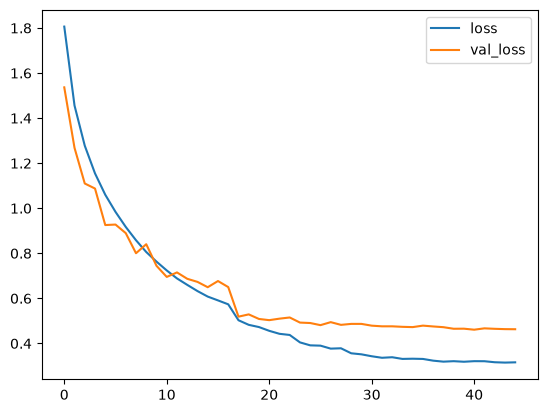

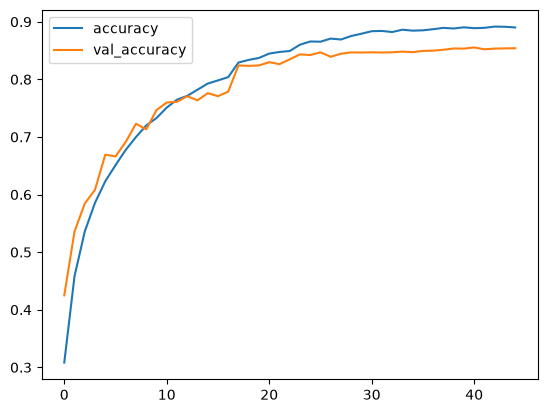

In [105]:
losses_13 = pd.DataFrame(history_13.history)

losses_13[["loss", "val_loss"]].plot()

losses_13[["accuracy", "val_accuracy"]].plot()


In [106]:
Path("results").mkdir(exist_ok=True)

results_13 = pd.DataFrame(history_13.history)
results_13.index += 1
results_13.index.name = "Epoch"

results_13.to_csv(
    "results/experiment_13_history.csv"
)

print("Experiment 13 results saved!")


Experiment 13 results saved!


# Experiment 14

A new version of the Experiment 11 architecture, with the L2 Regularization

In [108]:
tf.keras.utils.set_random_seed(42)

# Load Experiment 11 architecture
base_model = load_model(
    "models/exp11_extended_best.keras",
    compile=False
)

# Add L2 Regularization
def add_l2(layer):
    config = layer.get_config()

    if isinstance(layer, (Conv2D, Dense)):
        config["kernel_regularizer"] = {
            "class_name": "L2",
            "config": {"l2": 0.0001}
        }

    return layer.__class__.from_config(config)

# Create a new model with fresh weights
model_14 = clone_model(
    base_model,
    clone_function=add_l2
)

model_14.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_14.summary()


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_8 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_5            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 304,810 (1.16 MB)

 Trainable params: 304,810 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

In [110]:
for layer in model_14.layers:
    if isinstance(layer, (Conv2D, Dense)):
        print(
            layer.name,
            "L2:", layer.kernel_regularizer
        )


conv2d_31 L2: <keras.src.regularizers.regularizers.L2 object at 0x000002C0E57AFE00>
conv2d_32 L2: <keras.src.regularizers.regularizers.L2 object at 0x000002C0E57E8080>
conv2d_33 L2: <keras.src.regularizers.regularizers.L2 object at 0x000002C0E57E8560>
conv2d_34 L2: <keras.src.regularizers.regularizers.L2 object at 0x000002C0E57AF560>
conv2d_35 L2: <keras.src.regularizers.regularizers.L2 object at 0x000002C0E5701C40>
conv2d_36 L2: <keras.src.regularizers.regularizers.L2 object at 0x000002C0E57E8500>
dense_20 L2: <keras.src.regularizers.regularizers.L2 object at 0x000002C0E57E8D70>
dense_21 L2: <keras.src.regularizers.regularizers.L2 object at 0x000002C0E57E93D0>


In [111]:
Path("models").mkdir(exist_ok=True)

reduce_lr_14 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

early_stop_14 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint_14 = ModelCheckpoint(
    filepath="models/exp14_best.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

history_14 = model_14.fit(
    x_fit,
    y_fit,
    epochs=45,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[
        reduce_lr_14,
        early_stop_14,
        checkpoint_14
    ]
)


Epoch 1/45
702/704 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.2766 - loss: 1.8896
Epoch 1: val_loss improved from None to 1.64632, saving model to models/exp14_best.keras

Epoch 1: finished saving model to models/exp14_best.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 32s 42ms/step - accuracy: 0.2768 - loss: 1.8892 - val_accuracy: 0.3766 - val_loss: 1.6463 - learning_rate: 0.0010
Epoch 2/45
702/704 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.4256 - loss: 1.5618
Epoch 2: val_loss improved from 1.64632 to 1.38641, saving model to models/exp14_best.keras

Epoch 2: finished saving model to models/exp14_best.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accuracy: 0.4256 - loss: 1.5616 - val_accuracy: 0.4850 - val_loss: 1.3864 - learning_rate: 0.0010
Epoch 3/45
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4978 - loss: 1.4024
Epoch 3: val_loss improved from 1.38641 to 1.29182, saving model to models/exp14_best.keras

Epoch 3: finished saving model to models/exp14_best.keras
704

In [112]:
val_loss_14, val_acc_14 = model_14.evaluate(x_val,y_val,verbose=0)

best_epoch_14 = np.argmin(history_14.history["val_loss"]) + 1

print("Experiment 14 - L2 Regularization")
print(f"Validation Accuracy: {val_acc_14 * 100:.2f}%")
print(f"Validation Loss (with L2): {val_loss_14:.4f}")
print(f"Best Epoch: {best_epoch_14}")
print(f"Epochs Completed: {len(history_14.history['loss'])}")


Experiment 14 - L2 Regularization
Validation Accuracy: 84.10%
Validation Loss (with L2): 0.5544
Best Epoch: 44
Epochs Completed: 45


<Axes: >

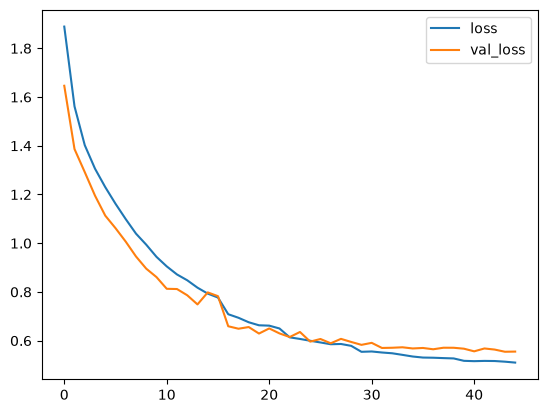

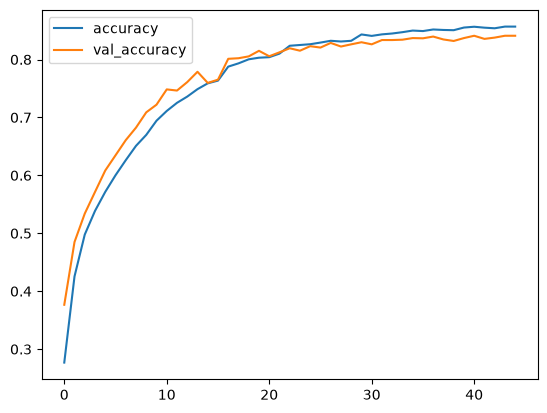

In [113]:
losses_14 = pd.DataFrame(history_14.history)

losses_14[["loss", "val_loss"]].plot()

losses_14[["accuracy", "val_accuracy"]].plot()

# Comparison of categories between the two models Exp 11 vs. Exp 14

In [150]:
models_compare = {
    "Experiment 11": load_model(
        "models/exp11_extended_best.keras",
        compile=False
    ),
    "Experiment 14": load_model(
        "models/exp14_best.keras",
        compile=False
    )
}

results = []

for name, current_model in models_compare.items():

    predictions = current_model.predict(
        x_val,
        batch_size=64,
        verbose=0
    )

    y_pred = np.argmax(predictions, axis=1)
    y_true = np.argmax(y_val, axis=1)

    accuracy = np.mean(y_pred == y_true) * 100

    # Cross-Entropy without L2 penalty
    ce_loss = tf.reduce_mean(
        tf.keras.losses.categorical_crossentropy(
            y_val, predictions
        )
    ).numpy()

    results.append({
        "Model": name,
        "Val Accuracy": round(accuracy, 2),
        "Cross Entropy": round(float(ce_loss), 4),
        "Parameters": current_model.count_params()
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.to_string(index=False))


        Model  Val Accuracy  Cross Entropy  Parameters
Experiment 11         85.54         0.4545      304810
Experiment 14         84.10         0.4602      304810


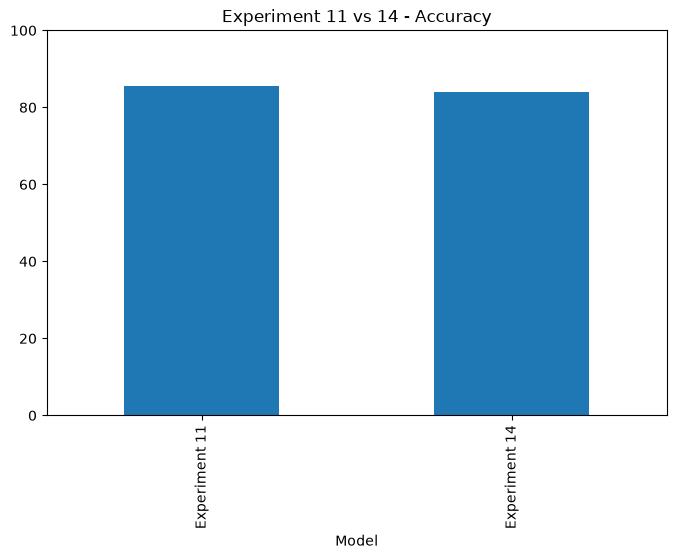

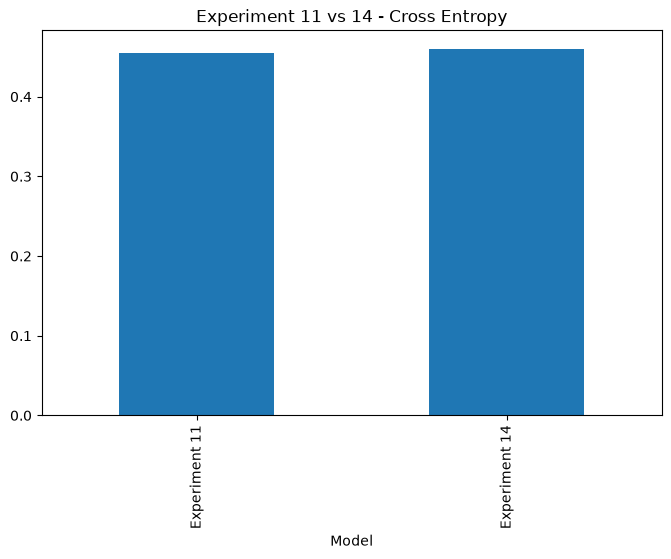

In [152]:

comparison_df.set_index("Model")[
    "Val Accuracy"
].plot(
    kind="bar",
    title="Experiment 11 vs 14 - Accuracy",
    figsize=(8, 5),
    ylim=(0, 100),
)
plt.show()

comparison_df.set_index("Model")[
    "Cross Entropy"
].plot(
    kind="bar",
    title="Experiment 11 vs 14 - Cross Entropy",
    figsize=(8, 5),
)
plt.show()


In [117]:
Path("results").mkdir(exist_ok=True)

results_14 = pd.DataFrame(history_14.history)
results_14.index = range(1, len(results_14) + 1)
results_14.index.name = "Epoch"

results_14.to_csv(
    "results/experiment_14_history.csv"
)

print("Experiment 14 results saved!")


Experiment 14 results saved!


# Model Comparison

Model Comparison - All CNN Experiments


In [120]:
models_dict = {
    "Exp 01 - Baseline": ("model", None),
    "Exp 02 - Dropout": ("dropout_model", None),
    "Exp 03 - RandomFlip": ("flip_model", None),
    "Exp 04 - BatchNorm": ("bn_model", None),
    "Exp 05 - Translation": ("translation_model", None),

    "Exp 06 - CNN 3x3": ("model_07", None),
    "Exp 08 - Deeper CNN": ("model_08", None),
    "Exp 09 - ReduceLR": ("model_09", None),
    "Exp 10 - Deeper CNN": ("model_10", None),

    "Exp 11 - GAP": (
        "model_11",
        "models/exp11_extended_best.keras"
    ),

    "Exp 12 - RandomContrast": (
        "model_12",
        "models/exp12_best.keras"
    ),

    "Exp 13 - Dropout 0.4": (
        "model_13",
        "models/exp13_best.keras"
    ),

    "Exp 14 - L2": (
        "model_14",
        "models/exp14_best.keras"
    )
}

results = []
y_true = np.argmax(y_val, axis=1)

for name, (model_name, saved_path) in models_dict.items():

    # Prefer saved checkpoints when available
    if saved_path and Path(saved_path).exists():
        current_model = load_model(
            saved_path,
            compile=False
        )
    else:
        current_model = globals().get(model_name)

    if current_model is None:
        print(f"Skipping {name}: model not found")
        continue

    # Predict on validation data
    predictions = current_model.predict(
        x_val,
        batch_size=64,
        verbose=0
    )

    y_pred = np.argmax(predictions, axis=1)

    # Accuracy
    val_accuracy = np.mean(y_pred == y_true) * 100

    # Cross-Entropy without L2 penalty
    val_ce = tf.reduce_mean(
        tf.keras.losses.categorical_crossentropy(
            y_val,
            predictions
        )
    ).numpy()

    results.append({
        "Model": name,
        "Val Accuracy": round(float(val_accuracy), 2),
        "Val Cross-Entropy": round(float(val_ce), 4),
        "Parameters": current_model.count_params()
    })

# Create comparison DataFrame
comparison_df = pd.DataFrame(results)

if comparison_df.empty:
    print("No models found.")
else:
    # Sort by lowest Cross-Entropy
    comparison_df = comparison_df.sort_values(
        by=["Val Cross-Entropy", "Val Accuracy"],
        ascending=[True, False]
    ).reset_index(drop=True)

    print(comparison_df.to_string(index=False))

    # Best model by Cross-Entropy
    print("\nBest Model by Cross-Entropy:")
    print(comparison_df.iloc[0].to_string())

    # Best model by Accuracy
    print("\nBest Model by Accuracy:")
    best_acc_idx = comparison_df["Val Accuracy"].idxmax()
    print(comparison_df.loc[best_acc_idx].to_string())

    # Save results for GitHub
    Path("results").mkdir(exist_ok=True)

    comparison_df.to_csv(
        "results/model_comparison.csv",
        index=False
    )

    print("\nModel comparison saved successfully!")


                  Model  Val Accuracy  Val Cross-Entropy  Parameters
           Exp 11 - GAP         85.54             0.4545      304810
            Exp 14 - L2         84.10             0.4602      304810
   Exp 13 - Dropout 0.4         85.54             0.4610      304810
      Exp 09 - ReduceLR         84.96             0.4652      402986
Exp 12 - RandomContrast         84.38             0.4710      304810
    Exp 10 - Deeper CNN         84.70             0.4914      550570
    Exp 08 - Deeper CNN         79.68             0.5950      402986
       Exp 06 - CNN 3x3         76.78             0.6842      612042
   Exp 05 - Translation         75.20             0.7098      446826
     Exp 04 - BatchNorm         71.56             0.8077      447210
    Exp 03 - RandomFlip         72.26             0.8217      446826
       Exp 02 - Dropout         70.36             0.8739      446826
      Exp 01 - Baseline         68.78             0.9295      446826

Best Model by Cross-Entropy:
Mode

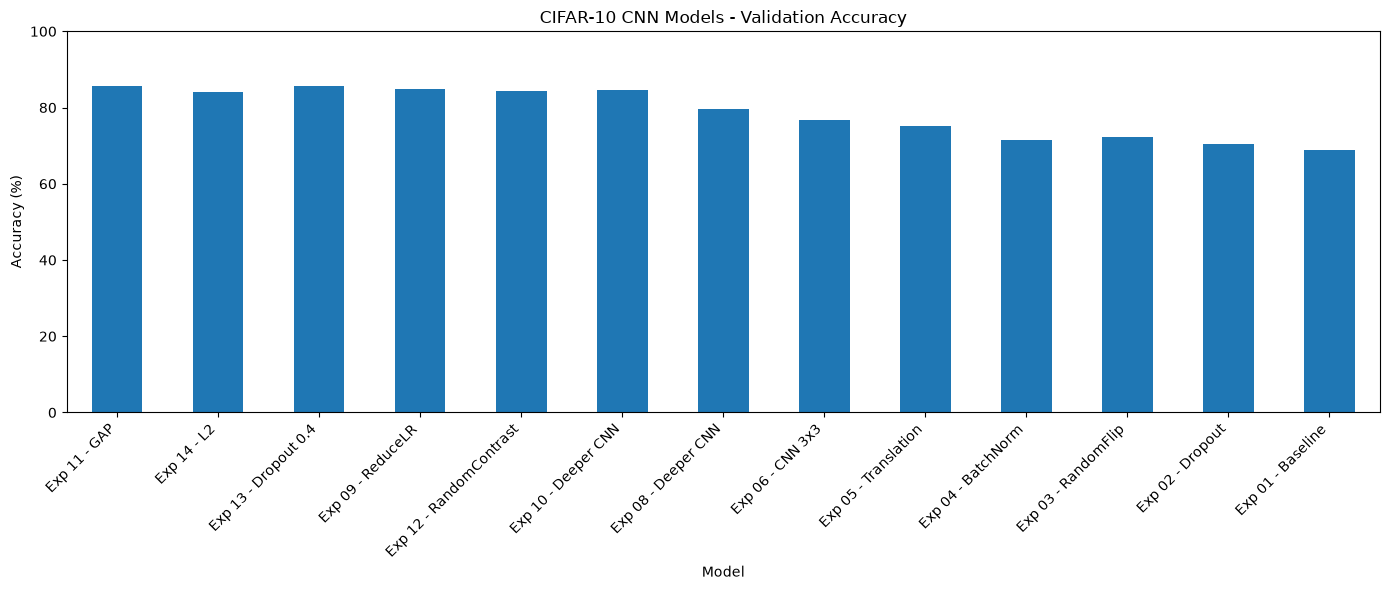

In [122]:
comparison_df.set_index("Model")["Val Accuracy"].plot(
    kind="bar",
    figsize=(14, 6),
    title="CIFAR-10 CNN Models - Validation Accuracy",
    ylabel="Accuracy (%)",
    ylim=(0, 100),
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "results/all_models_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


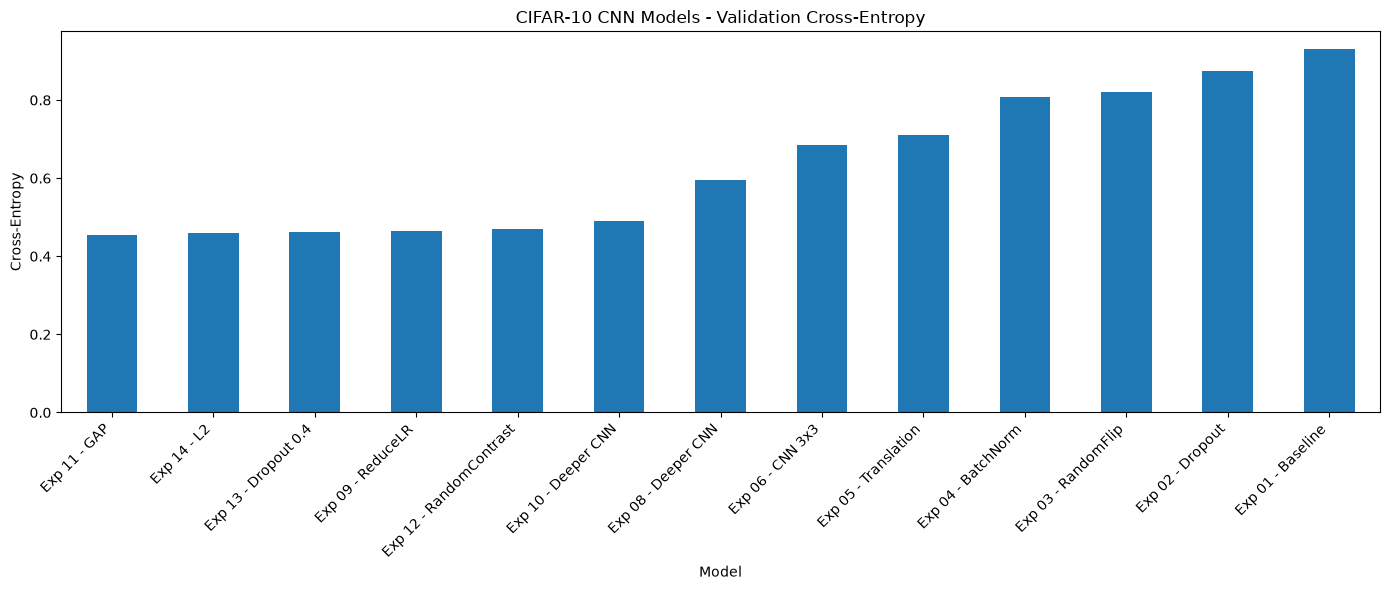

In [123]:
comparison_df.set_index("Model")["Val Cross-Entropy"].plot(
    kind="bar",
    figsize=(14, 6),
    title="CIFAR-10 CNN Models - Validation Cross-Entropy",
    ylabel="Cross-Entropy",
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "results/all_models_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [125]:
# Load best saved model
final_model = load_model(
    "models/exp11_extended_best.keras"
)

# Final Test Evaluation
test_loss, test_accuracy = final_model.evaluate(
    x_test,
    y_cat_test,
    batch_size=64,
    verbose=0
)

print("=== CIFAR-10 FINAL TEST RESULTS ===")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print(f"Total Parameters: {final_model.count_params():,}")


=== CIFAR-10 FINAL TEST RESULTS ===
Test Accuracy: 84.93%
Test Loss: 0.4850
Total Parameters: 304,810


In [ ]:
Path("results").mkdir(exist_ok=True)

final_results = {
    "model": "Experiment 11 - GlobalAveragePooling2D",
    "dataset": "CIFAR-10",
    "validation_accuracy": 0.8554,
    "validation_loss": 0.4545,
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "parameters": final_model.count_params(),
    "test_samples": len(x_test)
}

with open("results/final_test_results.json", "w") as f:
    json.dump(final_results, f, indent=4)


# THANK YOU 